# Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

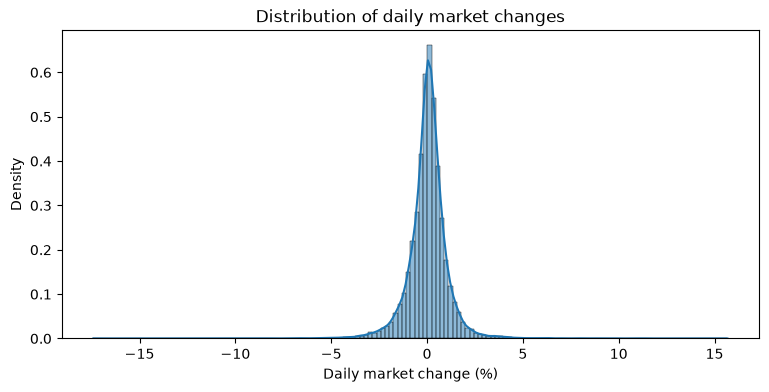

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

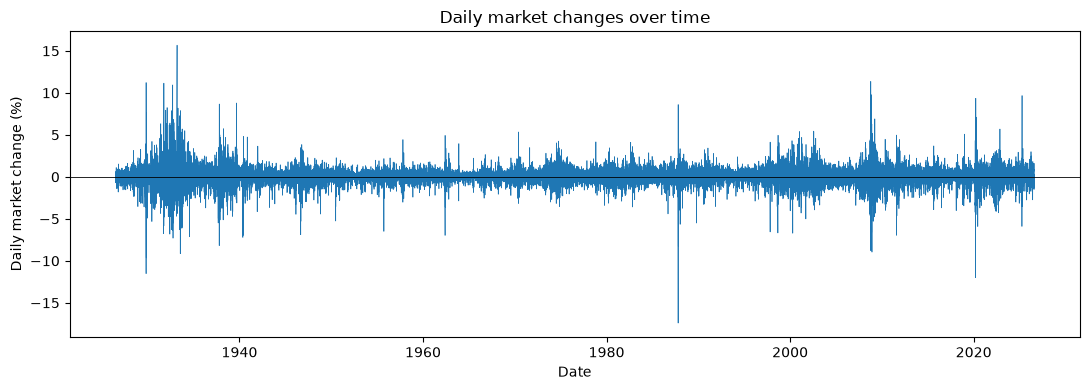

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

In [4]:
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)

## 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [5]:
df['market_return_cat'] = np.where(df['market_return_pct'] > 0 , 'Up' , 'Down (and flat)')
df[['market_return_pct','market_return_cat']]

,market_return_pct,market_return_cat
0,0.10,Up
1,0.46,Up
2,0.18,Up
3,0.10,Up
4,0.23,Up
...,...,...
26291,0.17,Up
26292,0.29,Up
26293,-1.50,Down (and flat)
26294,1.61,Up


In [6]:
df['y_t'] = df['market_return_cat']
df['y_tp1'] = df['market_return_cat'].shift(-1) # Shift into the future

### Cross Tab

In [7]:
tab = pd.crosstab(df['y_t'], df['y_tp1'])
tab

y_tp1,Down (and flat),Up
y_t,,
Down (and flat),5909,5999
Up,5999,8388


<Axes: xlabel='y_tp1', ylabel='y_t'>

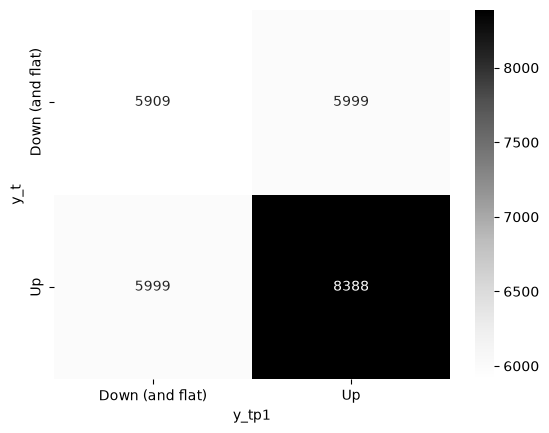

In [8]:
sns.heatmap(tab, annot=True, fmt='.0f', cmap='Greys')

### Joint PMF

In [9]:
jointpmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
jointpmf

y_tp1,Down (and flat),Up
y_t,,
Down (and flat),0.224720,0.228142
Up,0.228142,0.318996


<Axes: xlabel='y_tp1', ylabel='y_t'>

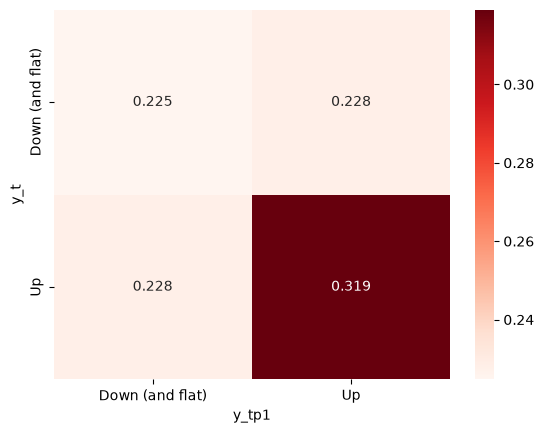

In [10]:
sns.heatmap(jointpmf, annot=True, fmt='.3f', cmap='Reds')

### Marginal PMF

In [11]:
marginalpmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize = True, margins = True)
marginalpmf

y_tp1,Down (and flat),Up,All
y_t,,,
Down (and flat),0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


<Axes: xlabel='y_tp1', ylabel='y_t'>

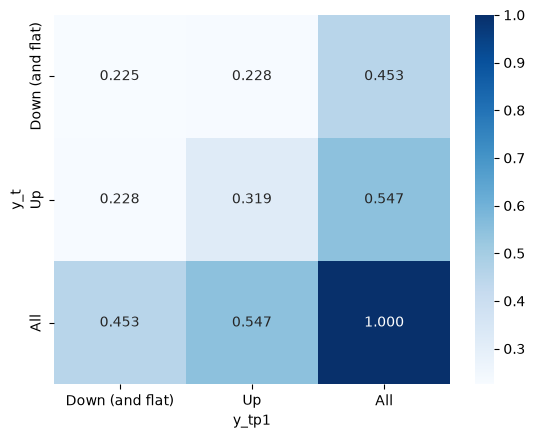

In [12]:
sns.heatmap(marginalpmf, annot=True, fmt='.3f', cmap='Blues')

### Conditional PMF

In [13]:
conditionalpmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize = 'index')
conditionalpmf

y_tp1,Down (and flat),Up
y_t,,
Down (and flat),0.496221,0.503779
Up,0.416974,0.583026


<Axes: xlabel='y_tp1', ylabel='y_t'>

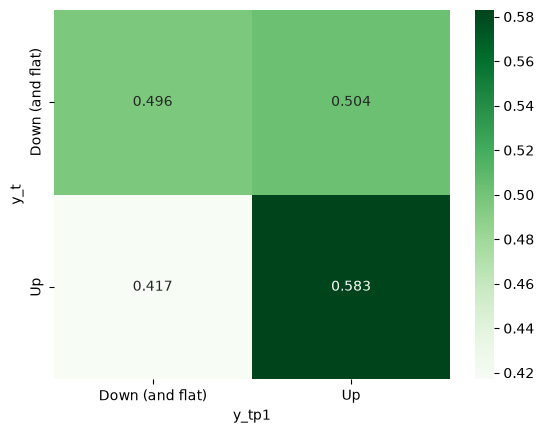

In [14]:
sns.heatmap(conditionalpmf, annot=True, fmt='.3f', cmap='Greens')

### Questions/Interpretations

<div class='alert alert-success'>
<b>Question:</b> Are up transitions more or less common than down transitions?

<b>Answer:</b> 
- The transitions from up to down are less common than down to up transitions. 
- Marginal PMF for both transitions are same, but the conditional PMF gives different values because the number of total values for being 'Up' today is more.
- Hence, we can say that there is a higher chance tomorrow will be up given today is down, than tomorrow will be down given today is up.
</div>

<div class='alert alert-success'>
<b>Question:</b> Are you more likely to transition to an Up day from a Down or Up day?

<b>Answer:</b>
- We transit from down to up 5999 times, while from up to up 8388 times.
- Hence, we are more likely to transition to a Up day given today is Up day, than today being a down day.
- To say in simple terms, if we have a Up day today, the probability that tomorrow will be an Up day is higher than Down day tomorrow.
</div>

## 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [15]:
df['pct_bin'] = pd.cut(
    df['market_return_pct'],
    bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf],
    labels=['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
)

df['y_t_bin'] = df['pct_bin']
df['y_tp1_bin'] = df['pct_bin'].shift(-1)

### Cross Tab

In [16]:
bin_tab = pd.crosstab(df['y_t_bin'], df['y_tp1_bin'])
bin_tab

y_tp1_bin,Large loss,Small loss,Near zero,Small gain,Large gain
y_t_bin,,,,,
Large loss,561,715,238,731,514
Small loss,932,2331,898,2571,720
Near zero,245,1104,551,1297,244
Small gain,657,2631,1447,4192,857
Large gain,364,671,306,994,524


<Axes: xlabel='y_tp1_bin', ylabel='y_t_bin'>

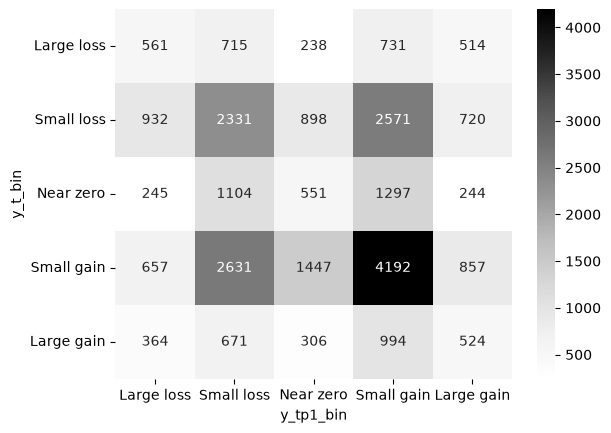

In [17]:
sns.heatmap(bin_tab, annot=True, fmt='.0f', cmap='Greys')

### Joint PMF

In [18]:
bin_jointpmf = pd.crosstab(df['y_t_bin'], df['y_tp1_bin'], normalize=True)
bin_jointpmf

y_tp1_bin,Large loss,Small loss,Near zero,Small gain,Large gain
y_t_bin,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928


<Axes: xlabel='y_tp1_bin', ylabel='y_t_bin'>

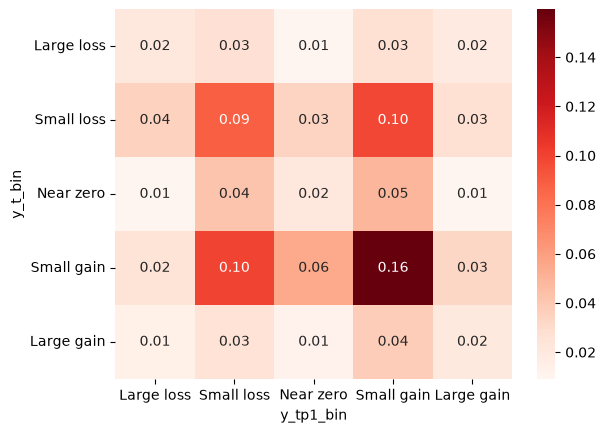

In [19]:
sns.heatmap(bin_jointpmf, annot=True, fmt='.2f', cmap='Reds')

### Marginal PMF

In [20]:
bin_marginalpmf = pd.crosstab(df['y_t_bin'], df['y_tp1_bin'], normalize = True, margins = True)
bin_marginalpmf

y_tp1_bin,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t_bin,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


<Axes: xlabel='y_tp1_bin', ylabel='y_t_bin'>

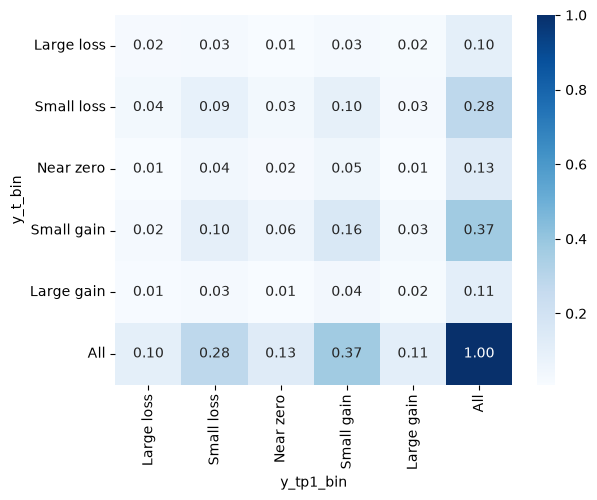

In [21]:
sns.heatmap(bin_marginalpmf, annot=True, fmt='.2f', cmap='Blues')

### Conditional PMF

In [22]:
bin_conditionalpmf = pd.crosstab(df['y_t_bin'], df['y_tp1_bin'], normalize = 'index')
bin_conditionalpmf

y_tp1_bin,Large loss,Small loss,Near zero,Small gain,Large gain
y_t_bin,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


<Axes: xlabel='y_tp1_bin', ylabel='y_t_bin'>

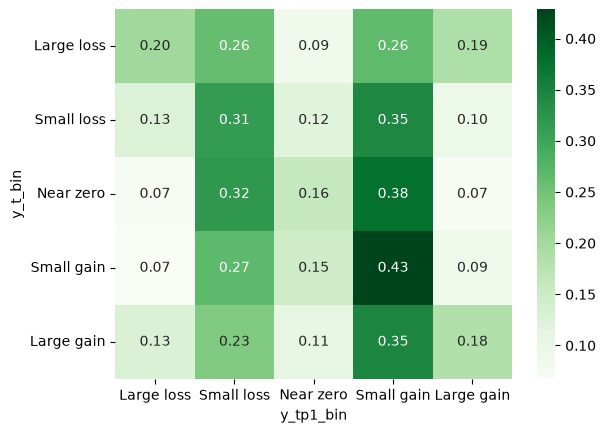

In [23]:
sns.heatmap(bin_conditionalpmf, annot=True, fmt='.2f', cmap='Greens')

### Questions/Interpretations

In [24]:
df['y_t_bin'].value_counts()

y_t_bin
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

<div class='alert alert-success'>
<b>Question:</b> How many days fall into each of the five bins? Which are the most or least common?

<b>Answer:</b> 
- Small gain has 9785 days, Small loss has 7452 days, Near zero has 3441 days, Large gain has 2859 days, and Large loss has 2759 days.
- Most common is "Small gain" days with count 9785, and least common is "Large loss" days with count 2759.
</div>

<div class='alert alert-success'>
<b>Question:</b> Which transitions are most likely to occur? 

<b>Answer:</b>
- The most common transitions are between small loss and small gain 
- small loss to small gain (0.10), small loss to small loss (0.09), small gain to small loss (0.10), small gain to small gain (0.16)
- Most likely is small gain to small gain.
</div>

<div class='alert alert-success'>
<b>Question:</b> For each current state, which two future states are the most likely?

<b>Answer:</b>
- Large loss: Small gain (0.26) and Small loss (0.25).
- Small loss: Small gain (0.35) and Small loss (0.31).
- Near zero: Small gain (0.38) and Small loss (0.32).
- Small gain: Small gain (0.43) and Small loss (0.27).
- Large gain: Small gain (0.35) and Small loss (0.23).
- For all the current states, the most likely future states are Small gain or Small loss.
</div>

<div class='alert alert-success'>
<b>Question:</b> Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?

<b>Answer:</b>
- Overall, no row is close to the uniform mass distribution, as the total proportion of days is skewed towards small loss and small gain days. Hence, for each day, the most transitions lead towards those days.
- Among all cases, Large Loss and large gain days can be considered closest to uniform mass function with probability 0.2.
- If we try to predict the next day from the current data, the answer for each state based on conditional probability will be "small gain" day, which cannot be true.
- If that was the case, there is no way to explain how small gain days transition into other categories.
- As seen above, the sheer number of 'small gain' days is very high compared to others. It doesnt tell us much about the transition.
- Hence we can say, predicting the next state is difficult as the data is skewed.
</div>

In [25]:
df.groupby('y_t_bin')['market_return_pct_tp1'].describe()

,count,mean,std,min,25%,50%,75%,max
y_t_bin,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


<div class='alert alert-success'>
<b>Question:</b> For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow?

<b>Answer:</b>
- Expected percent return for tomorrow (Mean of return) : Large loss −0.038%, Small loss −0.044%, Near zero 0.015%, Small gain 0.107%, Large gain 0.163%. The general trend shows that if today was a loss, it is expected that it will same for tomorrow (mean is negative). Similarly, if there was a gain today, it is expected that tomorrow will be gain too (mean is positive)./
</div>

<div class='alert alert-success'>
<b>Question:</b> How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice.

<b>Answer:</b>
- Min/max :
    - Large loss = −17.41% and 11.22%
    - Small loss = −11.23% and 11.36%
    - Near zero = −8.19% and 5.49%
    - Small gain = −8.25% and 8.67%
    - Large gain = −12.00% and 15.67%
- The large loss and large gain days have the highest standard deviation.
- It is evident from the min/max range as well, as the range is highest for both classes.
- The high standard deviation and high ranges for large gain and large loss show the classes are highly volatile. 
- For large gain and large loss, tomorrow transition can be anything from staying the same or transitioning from large loss to large gain or large gain to large loss.
- Similarly for all cases, the percent range for each class for next day ranges from large gain to large loss. We cannot make decisions based on this as this is highly volatile.
</div>

## 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [26]:
df['pct_quan'] = pd.qcut(
    df['market_return_pct'],
    q=21)
df['y_t_quan'] = df['pct_quan']
df['y_tp1_quan'] = df['pct_quan'].shift(-1)

### Cross Tab

In [27]:
quan_tab = pd.crosstab(df['y_t_quan'], df['y_tp1_quan'])
quan_tab

y_tp1_quan,"(-17.411, -1.61]","(-1.61, -1.07]","(-1.07, -0.78]","(-0.78, -0.57]","(-0.57, -0.42]","(-0.42, -0.3]","(-0.3, -0.19]","(-0.19, -0.11]","(-0.11, -0.03]","(-0.03, 0.04]",...,"(0.11, 0.18]","(0.18, 0.26]","(0.26, 0.34]","(0.34, 0.44]","(0.44, 0.54]","(0.54, 0.67]","(0.67, 0.84]","(0.84, 1.09]","(1.09, 1.55]","(1.55, 15.67]"
y_t_quan,,,,,,,,,,,,,,,,,,,,,
"(-17.411, -1.61]",183,96,77,47,58,46,48,30,36,35,...,27,35,35,29,42,30,51,53,95,181
"(-1.61, -1.07]",128,89,84,58,61,52,58,44,38,61,...,41,35,40,45,42,48,48,76,66,96
"(-1.07, -0.78]",96,99,98,100,59,49,56,48,39,54,...,52,62,59,43,36,54,48,61,66,70
"(-0.78, -0.57]",74,97,81,73,71,65,62,41,56,63,...,47,51,40,60,56,60,47,64,67,55
"(-0.57, -0.42]",61,71,76,68,56,67,69,57,61,48,...,54,49,46,72,57,51,70,43,60,49
"(-0.42, -0.3]",54,75,66,76,72,58,60,64,51,56,...,49,58,55,51,54,68,69,41,51,51
"(-0.3, -0.19]",63,74,88,84,74,74,58,59,64,65,...,51,68,84,66,56,66,51,46,63,44
"(-0.19, -0.11]",40,62,64,83,57,62,73,64,50,60,...,62,65,49,58,58,40,51,49,52,31
"(-0.11, -0.03]",35,53,64,64,66,65,61,65,62,72,...,65,64,58,66,62,50,56,47,38,40


<Axes: xlabel='y_tp1_quan', ylabel='y_t_quan'>

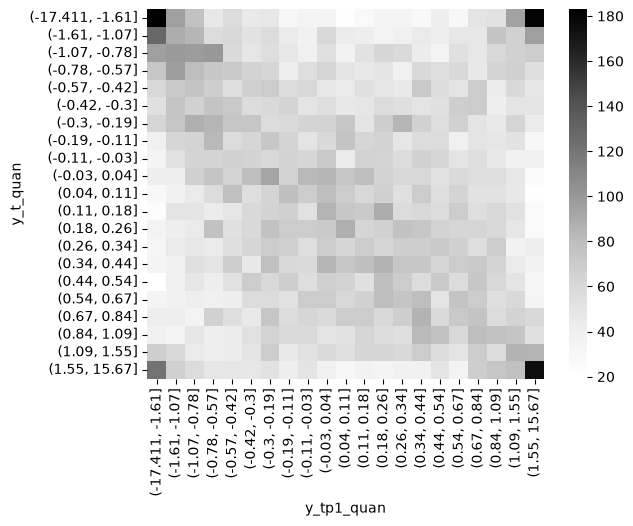

In [28]:
sns.heatmap(quan_tab, cmap='Greys')

### Joint PMF

In [29]:
quan_jointpmf = pd.crosstab(df['y_t_quan'], df['y_tp1_quan'], normalize=True)
quan_jointpmf

y_tp1_quan,"(-17.411, -1.61]","(-1.61, -1.07]","(-1.07, -0.78]","(-0.78, -0.57]","(-0.57, -0.42]","(-0.42, -0.3]","(-0.3, -0.19]","(-0.19, -0.11]","(-0.11, -0.03]","(-0.03, 0.04]",...,"(0.11, 0.18]","(0.18, 0.26]","(0.26, 0.34]","(0.34, 0.44]","(0.44, 0.54]","(0.54, 0.67]","(0.67, 0.84]","(0.84, 1.09]","(1.09, 1.55]","(1.55, 15.67]"
y_t_quan,,,,,,,,,,,,,,,,,,,,,
"(-17.411, -1.61]",0.006959,0.003651,0.002928,0.001787,0.002206,0.001749,0.001825,0.001141,0.001369,0.001331,...,0.001027,0.001331,0.001331,0.001103,0.001597,0.001141,0.001940,0.002016,0.003613,0.006883
"(-1.61, -1.07]",0.004868,0.003385,0.003195,0.002206,0.002320,0.001978,0.002206,0.001673,0.001445,0.002320,...,0.001559,0.001331,0.001521,0.001711,0.001597,0.001825,0.001825,0.002890,0.002510,0.003651
"(-1.07, -0.78]",0.003651,0.003765,0.003727,0.003803,0.002244,0.001863,0.002130,0.001825,0.001483,0.002054,...,0.001978,0.002358,0.002244,0.001635,0.001369,0.002054,0.001825,0.002320,0.002510,0.002662
"(-0.78, -0.57]",0.002814,0.003689,0.003080,0.002776,0.002700,0.002472,0.002358,0.001559,0.002130,0.002396,...,0.001787,0.001940,0.001521,0.002282,0.002130,0.002282,0.001787,0.002434,0.002548,0.002092
"(-0.57, -0.42]",0.002320,0.002700,0.002890,0.002586,0.002130,0.002548,0.002624,0.002168,0.002320,0.001825,...,0.002054,0.001863,0.001749,0.002738,0.002168,0.001940,0.002662,0.001635,0.002282,0.001863
"(-0.42, -0.3]",0.002054,0.002852,0.002510,0.002890,0.002738,0.002206,0.002282,0.002434,0.001940,0.002130,...,0.001863,0.002206,0.002092,0.001940,0.002054,0.002586,0.002624,0.001559,0.001940,0.001940
"(-0.3, -0.19]",0.002396,0.002814,0.003347,0.003195,0.002814,0.002814,0.002206,0.002244,0.002434,0.002472,...,0.001940,0.002586,0.003195,0.002510,0.002130,0.002510,0.001940,0.001749,0.002396,0.001673
"(-0.19, -0.11]",0.001521,0.002358,0.002434,0.003156,0.002168,0.002358,0.002776,0.002434,0.001902,0.002282,...,0.002358,0.002472,0.001863,0.002206,0.002206,0.001521,0.001940,0.001863,0.001978,0.001179
"(-0.11, -0.03]",0.001331,0.002016,0.002434,0.002434,0.002510,0.002472,0.002320,0.002472,0.002358,0.002738,...,0.002472,0.002434,0.002206,0.002510,0.002358,0.001902,0.002130,0.001787,0.001445,0.001521


<Axes: xlabel='y_tp1_quan', ylabel='y_t_quan'>

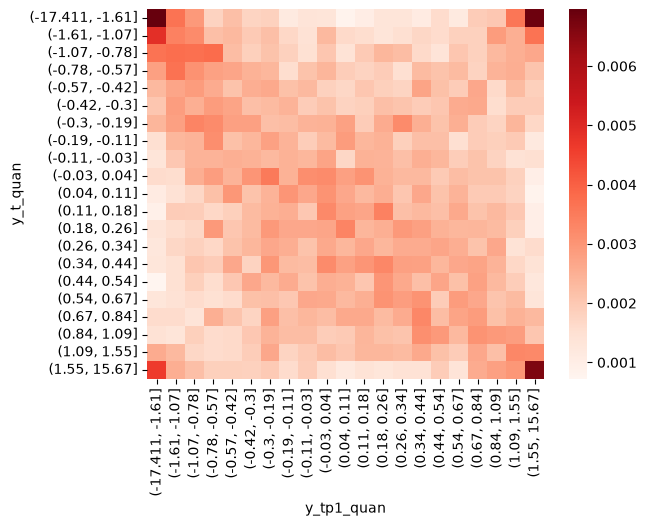

In [30]:
sns.heatmap(quan_jointpmf, cmap='Reds')

<Axes: xlabel='y_tp1_quan', ylabel='y_t_quan'>

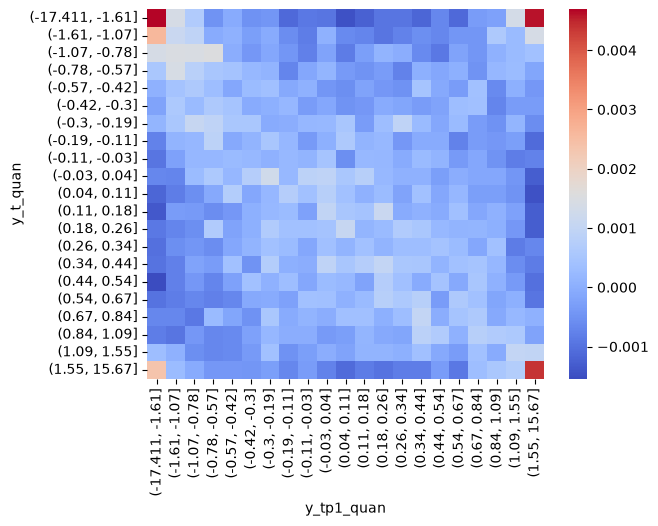

In [31]:
sns.heatmap(quan_jointpmf - (1/21)**2, cmap = 'coolwarm')

### Conditional PMF

In [32]:
quan_conditionalpmf = pd.crosstab(df['y_t_quan'], df['y_tp1_quan'], normalize = 'index')
quan_conditionalpmf

y_tp1_quan,"(-17.411, -1.61]","(-1.61, -1.07]","(-1.07, -0.78]","(-0.78, -0.57]","(-0.57, -0.42]","(-0.42, -0.3]","(-0.3, -0.19]","(-0.19, -0.11]","(-0.11, -0.03]","(-0.03, 0.04]",...,"(0.11, 0.18]","(0.18, 0.26]","(0.26, 0.34]","(0.34, 0.44]","(0.44, 0.54]","(0.54, 0.67]","(0.67, 0.84]","(0.84, 1.09]","(1.09, 1.55]","(1.55, 15.67]"
y_t_quan,,,,,,,,,,,,,,,,,,,,,
"(-17.411, -1.61]",0.145817,0.076494,0.061355,0.037450,0.046215,0.036653,0.038247,0.023904,0.028685,0.027888,...,0.021514,0.027888,0.027888,0.023108,0.033466,0.023904,0.040637,0.042231,0.075697,0.144223
"(-1.61, -1.07]",0.102155,0.071030,0.067039,0.046289,0.048683,0.041500,0.046289,0.035116,0.030327,0.048683,...,0.032721,0.027933,0.031923,0.035914,0.033520,0.038308,0.038308,0.060654,0.052674,0.076616
"(-1.07, -0.78]",0.074650,0.076983,0.076205,0.077760,0.045879,0.038103,0.043546,0.037325,0.030327,0.041991,...,0.040435,0.048212,0.045879,0.033437,0.027994,0.041991,0.037325,0.047434,0.051322,0.054432
"(-0.78, -0.57]",0.057813,0.075781,0.063281,0.057031,0.055469,0.050781,0.048438,0.032031,0.043750,0.049219,...,0.036719,0.039844,0.031250,0.046875,0.043750,0.046875,0.036719,0.050000,0.052344,0.042969
"(-0.57, -0.42]",0.049593,0.057724,0.061789,0.055285,0.045528,0.054472,0.056098,0.046341,0.049593,0.039024,...,0.043902,0.039837,0.037398,0.058537,0.046341,0.041463,0.056911,0.034959,0.048780,0.039837
"(-0.42, -0.3]",0.044046,0.061175,0.053834,0.061990,0.058728,0.047308,0.048940,0.052202,0.041599,0.045677,...,0.039967,0.047308,0.044861,0.041599,0.044046,0.055465,0.056281,0.033442,0.041599,0.041599
"(-0.3, -0.19]",0.045952,0.053975,0.064187,0.061269,0.053975,0.053975,0.042305,0.043034,0.046681,0.047411,...,0.037199,0.049599,0.061269,0.048140,0.040846,0.048140,0.037199,0.033552,0.045952,0.032093
"(-0.19, -0.11]",0.033167,0.051410,0.053068,0.068823,0.047264,0.051410,0.060531,0.053068,0.041459,0.049751,...,0.051410,0.053897,0.040630,0.048093,0.048093,0.033167,0.042289,0.040630,0.043118,0.025705
"(-0.11, -0.03]",0.029215,0.044240,0.053422,0.053422,0.055092,0.054257,0.050918,0.054257,0.051753,0.060100,...,0.054257,0.053422,0.048414,0.055092,0.051753,0.041736,0.046745,0.039232,0.031720,0.033389


<Axes: xlabel='y_tp1_quan', ylabel='y_t_quan'>

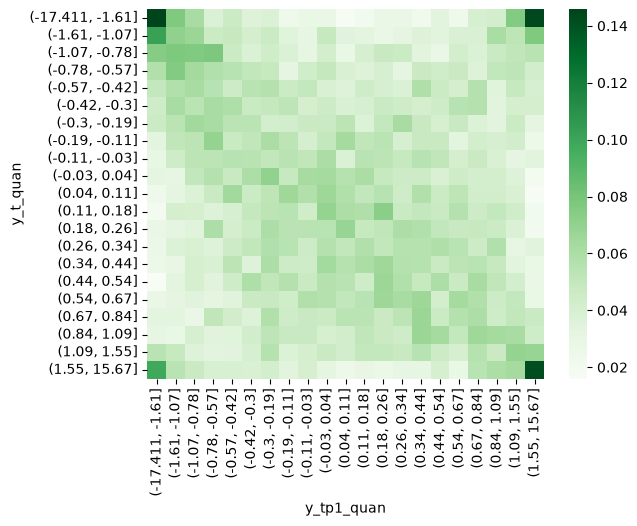

In [33]:
sns.heatmap(quan_conditionalpmf, cmap='Greens')

<Axes: xlabel='y_tp1_quan', ylabel='y_t_quan'>

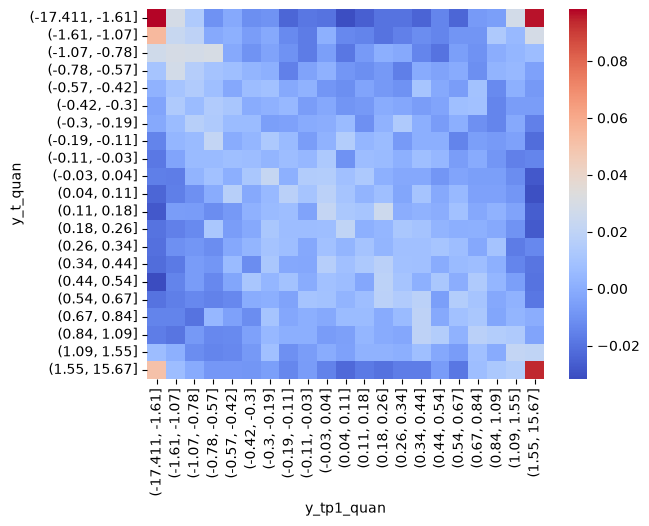

In [34]:
sns.heatmap(quan_conditionalpmf - 1/21, cmap = 'coolwarm')

### Questions/Interpretations

<div class='alert alert-success'>
<b>Question:</b> Do you see any obvious patterns in the joint PMF? Explain. 

<b>Answer:</b>
- After applying the factor to normalize, the four corners stand out compared to rest of the points.
- The four corners shows the highest proportions of transitions. They are interpreted as

|Today|Tomorrow|
|-|-|
|Extreme Losses|Extreme Gains|
|Extreme Losses|Extreme Losses|
|Extreme Gains|Extreme Gains|
|Extreme Gains|Extreme Losses|

- Hence, it is highly probable the market flips from one extremity to other overnight.
- The edges of the plot are near zero values, and they signify the proportions of transitions going from extremes to normals.
- Hence, the market seems unlikely to go from extreme to normal conditions the next day.
</div>

<div class='alert alert-success'>
<b>Question:</b> Do you see any obvious patterns in the conditional PMF? Explain. 

<b>Answer:</b>
- We see similar trends about the extreme conditions and normal conditions as joint pmf heatmap.
- Additionally the diagonal is almost neutral, which we interpret that the probability that the market tomorrow will stay in the same conditions as today is very low.
- The market is volatile and it keeps moving, either up or down, but not very likely to stay where it is.
</div>

In [35]:
quant_stat = df.groupby('y_t_quan', observed=True)['market_return_pct_tp1'].describe()
quant_stat

,count,mean,std,min,25%,50%,75%,max
y_t_quan,,,,,,,,
"(-17.411, -1.61]",1255.0,-0.013713,2.140465,-17.41,-0.9150,-0.02,0.9000,11.22
"(-1.61, -1.07]",1253.0,-0.076712,1.285882,-7.36,-0.7400,-0.02,0.6000,6.36
"(-1.07, -0.78]",1286.0,-0.097084,1.227976,-8.79,-0.7100,-0.03,0.4700,11.36
"(-0.78, -0.57]",1280.0,-0.058594,1.049607,-8.28,-0.5800,0.00,0.4925,6.16
"(-0.57, -0.42]",1230.0,-0.024211,0.989470,-6.89,-0.4675,0.02,0.4675,4.56
"(-0.42, -0.3]",1226.0,-0.022692,1.024761,-11.23,-0.4975,0.02,0.5000,6.37
"(-0.3, -0.19]",1371.0,-0.030241,0.930389,-3.94,-0.4950,0.03,0.4100,7.37
"(-0.19, -0.11]",1206.0,-0.014303,0.835663,-3.40,-0.4200,0.03,0.4100,4.76
"(-0.11, -0.03]",1198.0,0.025860,0.853220,-6.00,-0.3900,0.03,0.4400,5.49


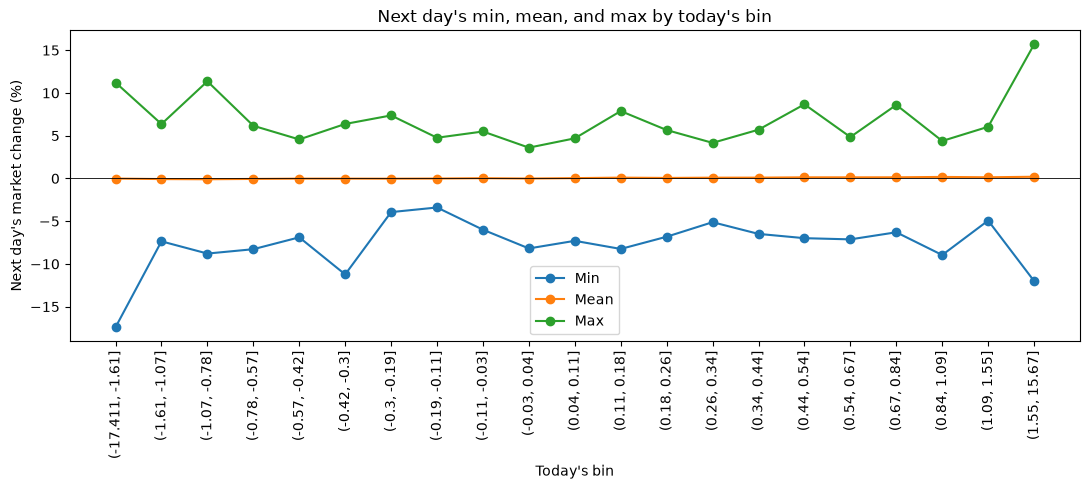

In [36]:
# Use of AI to write code for plot.
bins_x = np.arange(len(quant_stat))
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(bins_x, quant_stat['min'], marker='o', label='Min')
ax.plot(bins_x, quant_stat['mean'], marker='o', label='Mean')
ax.plot(bins_x, quant_stat['max'], marker='o', label='Max')
ax.axhline(0, color='black', linewidth=0.6)
ax.set_xticks(bins_x)
ax.set_xticklabels([str(b) for b in quant_stat.index], rotation=90)
ax.set(xlabel="Today's bin", ylabel="Next day's market change (%)",
       title="Next day's min, mean, and max by today's bin")
ax.legend()
fig.tight_layout()
plt.show()

<div class='alert alert-success'>
<b>Question:</b> For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 

<b>Answer:</b>
- The mean for all quantiles is nearly flat and close to zero. There is a slight increase from the low bins to the high bins, showing a positive trend. The effect however is very small next to the day-to-day spread.
- The min/max spike at both ends of the plot, supporting over previous analysis that extreme cases are the most volatile and can jump from one end to other in a day. The middle bins mostly stay near zero, suggesting that mostly if today is a normal day, tommorow might be the same.
</div>

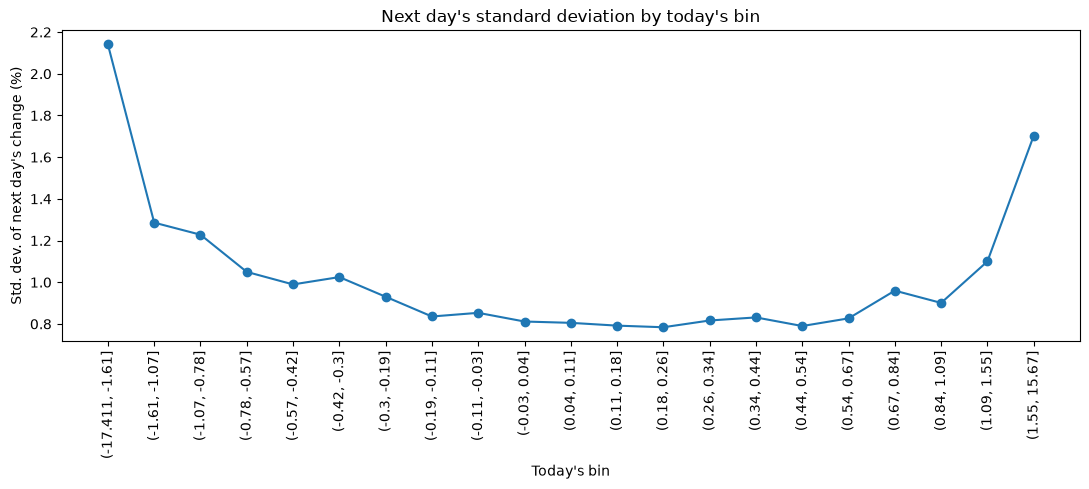

In [37]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(bins_x, quant_stat['std'], marker='o')
ax.set_xticks(bins_x)
ax.set_xticklabels([str(b) for b in quant_stat.index], rotation=90)
ax.set(xlabel="Today's bin", ylabel="Std. dev. of next day's change (%)",
       title="Next day's standard deviation by today's bin")
fig.tight_layout()
plt.show()

<div class='alert alert-success'>
<b>Question:</b> For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain.

<b>Answer:</b>
- The standard deviation of tomorrow's return is U-shaped across the bins. It is about 2.14 for the extreme losses quantile, falls to less than 1 in the middle bins, and rises again to about 1.70 at the extreme gains case.
- The left end is slightly higher than the right end, so we can say that extreme losses are more volatile to convert into extreme gains than extreme gains going to extreme losses.
</div>

In [38]:
df['market_return_pct'].mean()

np.float64(0.04300540006084576)

In [39]:
start_value = 100

# Apply each day's percent change to the running balance
df['value'] = start_value * (1 + df['market_return_pct'] / 100).cumprod()

final_value = df['value'].iloc[-1]
print(f"Start : ${start_value :,.2f}")
print(f"Final : ${final_value :,.2f}")

Start : $100.00
Final : $1,764,745.20


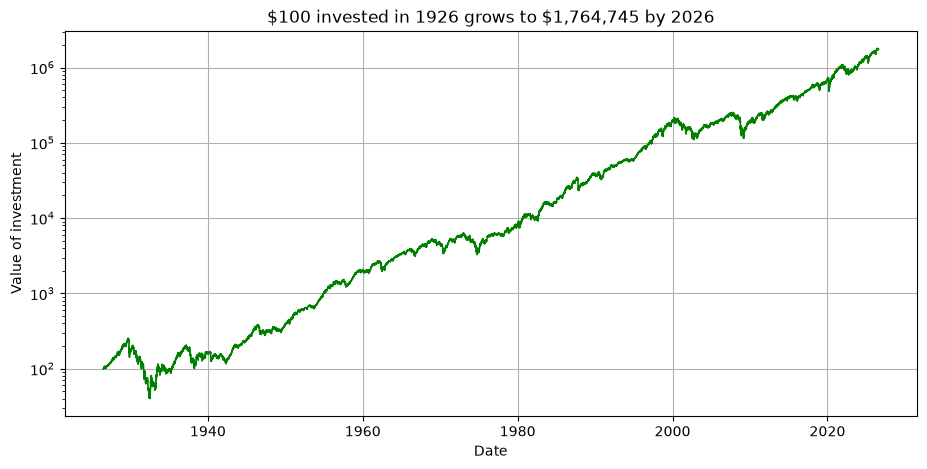

In [40]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(df['date'], df['value'], color='green', linewidth=1.2)
ax.set_yscale('log')
ax.grid(visible= True)
ax.set(xlabel='Date', 
       ylabel='Value of investment',
       title=f"\$100 invested in {df['date'].iloc[0]:%Y} grows to ${final_value:,.0f} by {df['date'].iloc[-1]:%Y}")
plt.show()

<div class='alert alert-success'>
<b>Question:</b> How easy is it to predict the market?

<b>Answer:</b>
- Based on the observed data, it is not easy to predict the market.
- As we saw in the 5 bin map and 21 quantile map, that extreme day can flip in either direction. 
- There is an almost equal probability for a bad day to flip to good day or stay a bad day.
- The means (expected value) for most of the regions is also very close to zero.
- The general pattern is extreme cases are most probable to stay in extreme scenario. And normal days are probable to stay in that region.
- Hence, we can predict if tomorrow will be a normal day or extreme day from today's data, but not percent of return.

<b>Analysis:</b>
- A separate analysis shows that the overall mean of the marker pct is positive.
- Similar number shows up when we plot the trend on a graph.
- If we invested $100 in 1926, we would have $1764745 in 2026 (without adjusting for inflation)
- Hence, overall we can say that over a long period of time, we can surely gain money from the market.
</div>